In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [15]:
# Upload Dataset
from google.colab import files

uploaded = files.upload()

Saving loan_approval.csv to loan_approval.csv


In [16]:
# Load Dataset
df = pd.read_csv("loan_approval.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (4278, 13)


,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2.0,Graduate,No,9600000,29900000.0,12.0,778.0,2400000.0,17600000.0,22700000.0,8000000.0,1
1,2,0.0,Not Graduate,Yes,4100000,12200000.0,8.0,417.0,2700000.0,2200000.0,8800000.0,3300000.0,0
2,3,3.0,Graduate,No,9100000,29700000.0,20.0,506.0,7100000.0,4500000.0,33300000.0,12800000.0,0
3,4,3.0,Graduate,No,8200000,30700000.0,8.0,467.0,18200000.0,3300000.0,23300000.0,7900000.0,0
4,5,5.0,Not Graduate,Yes,9800000,24200000.0,20.0,382.0,12400000.0,8200000.0,29400000.0,5000000.0,0


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4278 entries, 0 to 4277
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        4278 non-null   int64  
 1   no_of_dependents          4275 non-null   float64
 2   education                 4276 non-null   object 
 3   self_employed             4274 non-null   object 
 4   income_annum              4278 non-null   int64  
 5   loan_amount               4277 non-null   float64
 6   loan_term                 4277 non-null   float64
 7   cibil_score               4276 non-null   float64
 8   residential_assets_value  4277 non-null   float64
 9   commercial_assets_value   4277 non-null   float64
 10  luxury_assets_value       4276 non-null   float64
 11  bank_asset_value          4277 non-null   float64
 12  loan_status               4278 non-null   int64  
dtypes: float64(8), int64(3), object(2)
memory usage: 434.6+ KB


In [18]:
df.describe(include="all")

,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
count,4278.000000,4275.000000,4276,4274,4.278000e+03,4.277000e+03,4277.000000,4276.000000,4.277000e+03,4.277000e+03,4.276000e+03,4.277000e+03,4278.000000
unique,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Graduate,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,2147,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2139.500000,2.497778,NaN,NaN,5.063558e+06,1.515081e+07,10.904606,600.089102,7.465139e+06,4.983002e+06,1.512891e+07,4.982722e+06,0.621552
std,1235.096555,1.695374,NaN,NaN,2.807086e+06,9.048995e+06,5.707992,172.370617,6.500132e+06,4.402675e+06,9.100411e+06,3.251966e+06,0.485057
min,1.000000,0.000000,NaN,NaN,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00,0.000000
25%,1070.250000,1.000000,NaN,NaN,2.700000e+06,7.700000e+06,6.000000,454.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.400000e+06,0.000000
50%,2139.500000,3.000000,NaN,NaN,5.100000e+06,1.460000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06,1.000000
75%,3208.750000,4.000000,NaN,NaN,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06,1.000000


In [19]:
missing = df.isnull().sum()

print(missing)

id                          0
no_of_dependents            3
education                   2
self_employed               4
income_annum                0
loan_amount                 1
loan_term                   1
cibil_score                 2
residential_assets_value    1
commercial_assets_value     1
luxury_assets_value         2
bank_asset_value            1
loan_status                 0
dtype: int64


loan_status
1    2659
0    1619
Name: count, dtype: int64


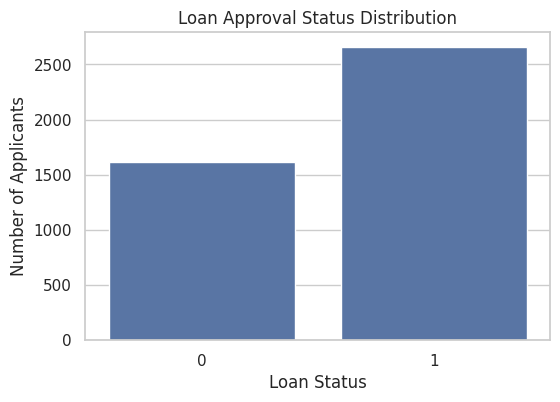

In [27]:
# Target Distribution
print(df["loan_status"].value_counts())


plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="loan_status")

plt.title("Loan Approval Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")

plt.show()

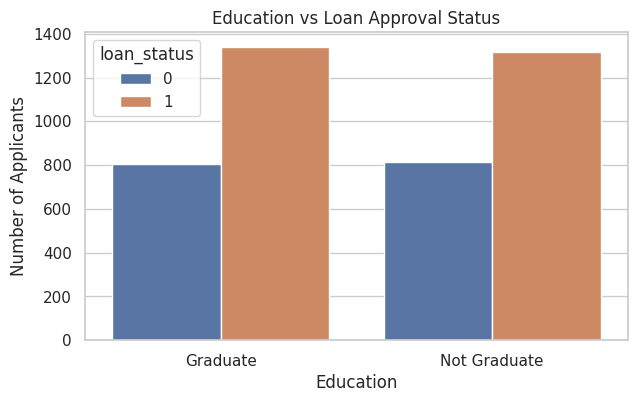

In [22]:
# Education vs Loan Status
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="education",
    hue="loan_status"
)

plt.title("Education vs Loan Approval Status")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")

plt.show()

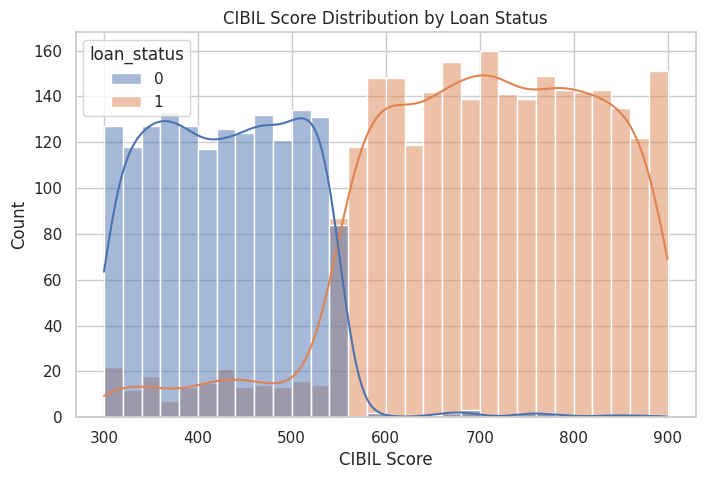

In [23]:
# CIBIL Score Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="cibil_score",
    hue="loan_status",
    kde=True,
    bins=30
)

plt.title("CIBIL Score Distribution by Loan Status")
plt.xlabel("CIBIL Score")
plt.ylabel("Count")

plt.show()

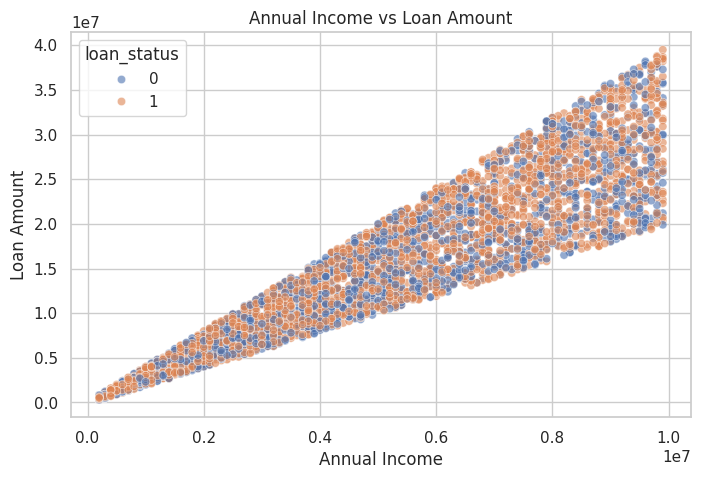

In [24]:
# Annual Income vs Loan Amount

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="income_annum",
    y="loan_amount",
    hue="loan_status",
    alpha=0.6
)

plt.title("Annual Income vs Loan Amount")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")

plt.show()

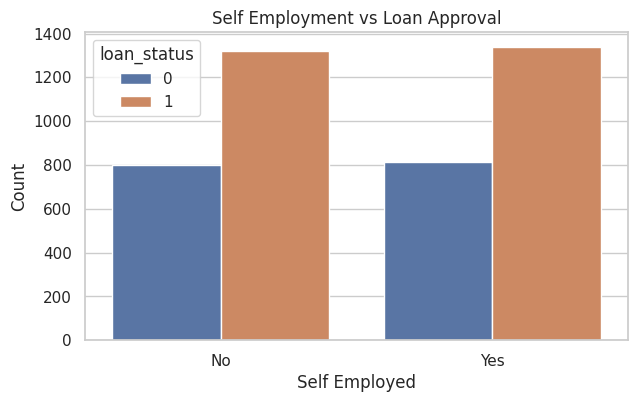

In [25]:
# Self Employment vs Loan Status
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="self_employed",
    hue="loan_status"
)

plt.title("Self Employment vs Loan Approval")
plt.xlabel("Self Employed")
plt.ylabel("Count")

plt.show()

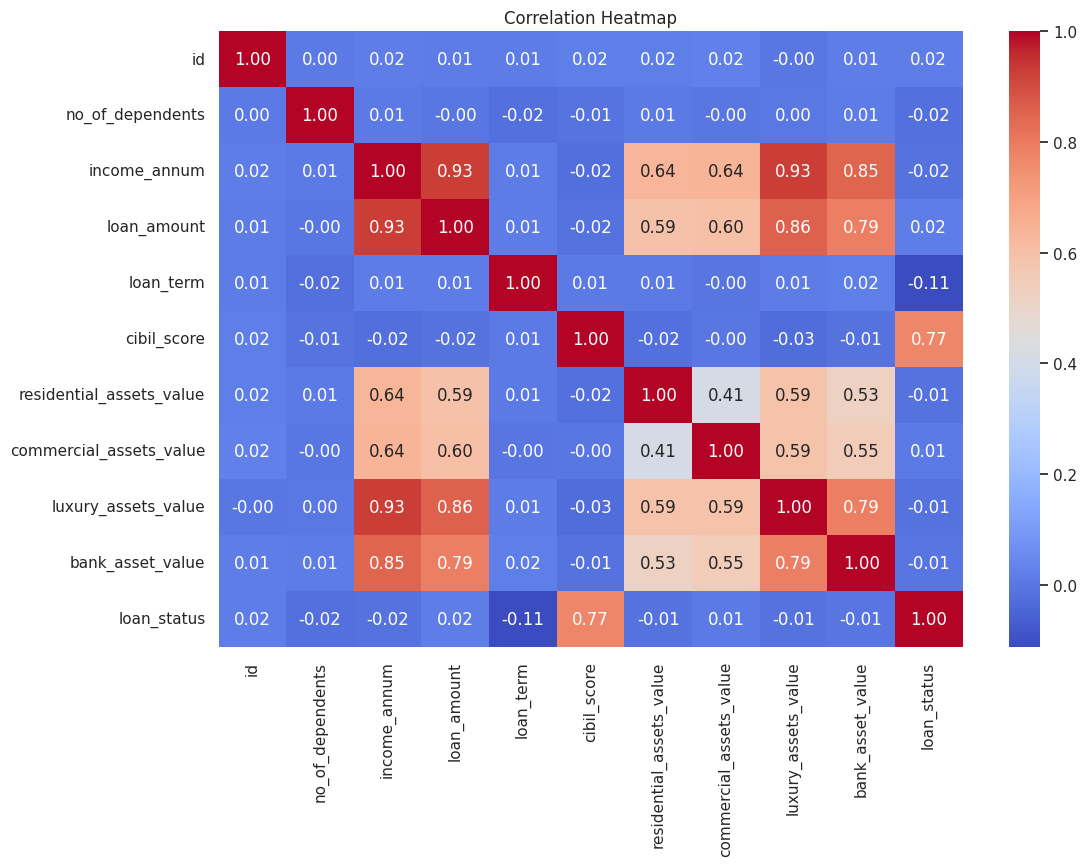

In [26]:
# Correlation Heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Observations

1. The dataset contains applicant financial and personal information.
2. Loan status is the target variable.
3. CIBIL score is an important credit-related feature.
4. Income and loan amount provide information about the applicant's financial profile.
5. Some columns contain missing values, which need to be handled before model training.
6. Categorical features such as education and self-employment need to be encoded before applying machine learning algorithms.